# Regression test selection

**Recipe 32** · Level 3 (Intermediate) · Decision type: `Score`

Score candidate tests against the behavior changed by a patch so Python can propose a focused regression suite.

Sources:

- S02: [TypeSafe AI: Primitives (Questions)](https://docs.typesafe.ai/primitives)
- S03: [TypeSafe AI: Confidence](https://docs.typesafe.ai/confidence)
- S04: [TypeSafe AI: How to build with TypeSafe](https://docs.typesafe.ai/concepts/how-to-build-with-system-one)
- S05: [TypeSafe AI: Example use cases](https://docs.typesafe.ai/concepts/use-case-map)

## What you will build

A regression-suite proposer. For each of 19 scored patches per split (plus 2 more, shown but never scored), Python holds a small candidate set of tests already gathered for that patch -- which tests exist to even consider is Python's job, not Jev's -- and Jev answers one `Score` question per (patch, candidate test) pair: how relevant is this test to the behavior the patch changes, against a four-level rubric Python wrote? Jev never selects, ranks, sizes, or weighs anything: Python takes back the expected score of every candidate, classifies each one (confident enough to trust, and if so, whether its most likely level clears a fixed cutoff), and composes a bounded regression suite from the candidates it trusts and judges relevant, ranked by that score and capped at a fixed size budget. By the end you will have looked at typed answers across the rubric, seen the rule, a small file-path-and-lexical baseline standing in for however the candidate set itself might otherwise be ranked, and the suite-composition function, then run an evaluation that reports per-candidate agreement with the rubric and selective-prediction numbers, the recall of each patch's gold-relevant tests within the proposed suite -- per patch and averaged across every patch -- against that baseline, and two counterfactuals showing exactly what the confidence gate and the size budget each cost when removed. The run replays 163 stored, synthetic answers (160 scored across 38 patches, 19 per split, plus 3 more across 2 more patches, shown in this notebook but never scored).


## Setup and run mode

The notebook runs from its own folder with the standard library and `jev_cookbook` only. `get_backend(fixtures=...)` replays the 163 stored answers in `fixtures/responses.json` offline; setting `JEV_COOKBOOK_LIVE=1` (see the README) swaps in live calls to the same question definition and changes nothing else. `run_header` states which mode ran, and every reported metric below carries that mode with it. The individual answers and per-example lines shown along the way are not reported metrics, so they may carry no label of their own; they come from the mode the header names.


In [1]:
from jev_cookbook import get_backend, load_helpers
from jev_cookbook.evaluation import (
    evaluate_outcomes,
    evaluate_selective,
    exact_agreement,
    mean_absolute_error,
    score_level,
    select_confidence_threshold,
    selective_curve,
)
from jev_cookbook.fixtures import load_inputs, load_labels, responses_path, select_split
from jev_cookbook.style import (
    apply_style,
    plot_answer_probabilities,
    plot_risk_coverage,
    run_header,
    show_answer,
)

apply_style()
helpers = load_helpers()  # this recipe's helpers.py, loaded by path
examples = load_inputs()
labels = load_labels()
backend = get_backend(fixtures=responses_path())
# N for the header is the number of examples the metrics are about: validation and test
# candidates. This recipe has no train split; demo examples are shown but never scored.
scored = [e for e in examples if e.split not in ("train", "demo")]

offline = backend.mode in ("synthetic", "scripted")
check = " (a pipeline check, not a Jev result)" if offline else ""
# CONTRIBUTING.md section 2: "a number from the validation split is a selection step, not a
# result." This label does not depend on the run mode, unlike `check` above: even a recorded or
# live run must not print a bare validation number. In an offline run the two combine, because a
# validation number is both a selection step and a pipeline check.
selection = " (a selection step, not a reported result)"

# Every example this notebook decides needs exactly one request, and this cache makes sure
# each one is decided once: the 3 demo candidates shown individually below, plus the 160
# scored validation and test candidates -- 163 requests in live mode, never more (the
# "measured" cell at the end counts this directly from `answered`, not by multiplying).
answered = {}
questions = None  # filled in by the "questions" cell below; decide() is first called after that


def decide(example):
    if example.id not in answered:
        answered[example.id] = backend.decide(helpers.build_state(example.fields), questions)[
            "relevance"
        ]
    return answered[example.id]


run_header(
    32,
    "Regression test selection",
    backend=backend,
    n_examples=len(scored),
)

Recipe 32: Regression test selection
Mode: offline replay of synthetic fixtures, pipeline check on a fixture sample of 160 examples
Metrics in this run are checks that the pipeline works. They are not Jev results.


## The state

The state is everything Jev sees, and Python builds it. Each example in `fixtures/inputs.jsonl` carries `fields`: a `task_id` (the patch this candidate belongs to), the `patch` description, the candidate `test` itself, and the candidate's own `changed_files` and `test_path` -- its source location, kept for the baseline and for tracing results, never for Jev. `build_state` passes on the patch description and the test text only; everything else stays in Python and is reattached to the outcome afterwards, so every classified candidate still traces back to its patch and its own file.


In [2]:
import json

demo = {e.fields["test_id"]: e for e in examples if e.split == "demo"}
example = demo["demo-discount-engine__test_subtotal_at_the_new_threshold_qualifies"]
print("Python has:")
print(json.dumps(example.fields, indent=2))
state = helpers.build_state(example.fields)
print("Jev sees:")
print(json.dumps(state, indent=2))

Python has:
{
  "task_id": "demo-discount-engine",
  "test_id": "demo-discount-engine__test_subtotal_at_the_new_threshold_qualifies",
  "patch": "This patch changes `apply_discount` in `billing/discount_engine.py` so that a subtotal of exactly $500, a newly added volume-discount threshold, now also qualifies; previously only subtotals strictly above $500 qualified.",
  "test": "def test_subtotal_at_the_new_threshold_qualifies():\n    order = make_order(subtotal=500.00)\n    assert order_after_pricing(order).total == 450.00",
  "changed_files": [
    "billing/discount_engine.py"
  ],
  "test_path": "tests/billing/test_subtotal_at_the_new_threshold_qualifies.py",
  "position": 1
}
Jev sees:
{
  "patch": "This patch changes `apply_discount` in `billing/discount_engine.py` so that a subtotal of exactly $500, a newly added volume-discount threshold, now also qualifies; previously only subtotals strictly above $500 qualified.",
  "test": "def test_subtotal_at_the_new_threshold_qualifies():\n

## The questions

There is one question, and it asks one thing: how relevant is this candidate test to the behavior this patch changes? A `Score` fits because the answer is a position on an ordered relevance scale, not a choice among unrelated categories, and the TypeSafe primitives documentation for `Score` (S02, https://docs.typesafe.ai/primitives/score) is explicit that the levels are the recipe's to define and are each judged on their own, not against their neighbours. Python builds the four levels from `RELEVANCE_LEVELS` in `helpers.py`, lowest to highest: `unrelated`, `same_area`, `exercises_change`, `direct_regression`. Each level below is written to stand alone: it says what the candidate test itself exercises, never "more relevant than the level above."

A `Score` answer's `score` is its headline field: the level number multiplied by its probability, summed over every level, so it is a position on the relevance spectrum that can fall between two levels. This is the **expected score**, a different quantity from the **modal level** ([`score_level`](../../docs/evaluation.md), the level with the single highest probability, ties going to the lowest one): the rule below and the per-candidate agreement further down act on the modal level, because a suite-membership decision needs one level to decide against, while the suite's own ranking uses the expected score, because a candidate whose whole distribution leans toward a high level should rank ahead of one that is merely tied for the same modal level.

A `Score` answer's [confidence](../../docs/glossary.md#confidence) is not the top probability. The published formula ([S03](https://docs.typesafe.ai/confidence)) is `1 - spread / even_spread`, clamped to 0 or above: `spread` is the probability-weighted distance, in levels, between the answer and its most likely level, and `even_spread` is the same kind of distance for a uniform spread over all levels, measured from the middle. For four levels (0 to 3), the middle is 1.5 and `even_spread = mean(|0-1.5|, |1-1.5|, |2-1.5|, |3-1.5|) = 1.0`. Probability placed on a level *next to* the peak lowers confidence less than the same probability placed on a level further away.

Arithmetic stays in Python on purpose ([S04](https://docs.typesafe.ai/concepts/how-to-build-with-system-one)): the fixed business cutoff, the confidence gate, and the size budget are all plain comparisons and a sort against numbers the model never computes itself, and nothing below ever asks Jev to rank, weigh, or size anything.


In [3]:
questions = helpers.build_questions()
relevance = questions["relevance"]
print(relevance.instructions)
for level, description in enumerate(relevance.criteria):
    print(f"  {level}  {description}")

How relevant is this candidate test to the behavior this patch changes? Judge only what this test itself exercises, not what the patch's description claims about the test, and not any other test.
  0  The test exercises code that has nothing to do with the module, function, or behavior the patch changes. Nothing the patch does could make this test start or stop passing.
  1  The test exercises the same module or feature area the patch touches, but not the function or branch the patch changes. A defect in the patch's own change could pass this test without being caught.
  2  The test calls the function or exercises the branch the patch changes, and would fail if that changed behavior were removed, but it does not exercise the exact edge case or boundary condition the patch adds or alters.
  3  The test exercises exactly the edge case, boundary, or condition the patch adds or alters, and would fail if the patch's own change were reverted.


## One answer up close

Before any aggregate number, look at three typed answers for two different patches. Each answer holds the expected `score`, a probability for every level, the confidence explained above, and a `provenance` line, here always `synthetic`, since nothing in this recipe's fixtures came from a real call. All three are `demo` candidates, so they illustrate the question without being scored anywhere below.


This patch changes `apply_discount` in `billing/discount_engine.py` so that a subtotal of exactly $500, a newly added volume-discount threshold, now also qualifies; previously only subtotals strictly above $500 qualified.

def test_subtotal_at_the_new_threshold_qualifies():
    order = make_order(subtotal=500.00)
    assert order_after_pricing(order).total == 450.00
Score: 2.78 (confidence 0.78)
  0 The test exercises code that has nothing to do with the module, function, or behavior the patch
    changes. Nothing the patch does could make this test start or stop passing.  0.02  
  1 The test exercises the same module or feature area the patch touches, but not the function or
    branch the patch changes. A defect in the patch's own change could pass this test without being
    caught.  0.03  #
  2 The test calls the function or exercises the branch the patch changes, and would fail if that
    changed behavior were removed, but it does not exercise the exact edge case or boundary
    

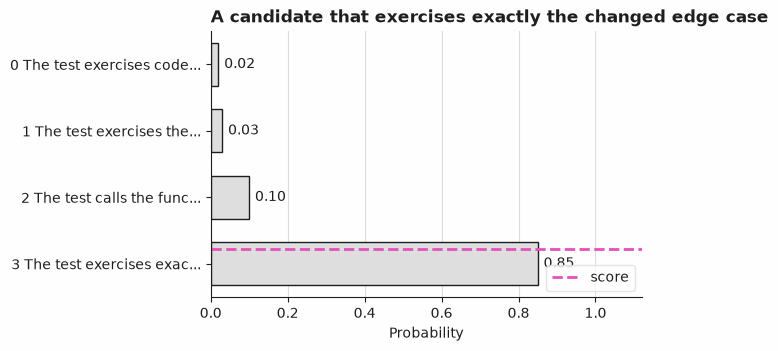

In [4]:
direct_example = demo["demo-discount-engine__test_subtotal_at_the_new_threshold_qualifies"]
direct_answer = decide(direct_example)
print(direct_example.fields["patch"])
print()
print(direct_example.fields["test"])
show_answer(direct_answer)
plot_answer_probabilities(
    direct_answer, title="A candidate that exercises exactly the changed edge case"
)

The patch adds a new volume-discount threshold at exactly $500; this candidate tests a cart whose total is exactly $500. That is the precise boundary the patch changes, so a human rubric calls it `direct_regression` (level 3): it would fail if the patch's own change were reverted. The stored answer puts `direct_regression` on top at high confidence: nearly all the probability sits on the top level, which is exactly what the confidence formula above rewards.


In [5]:
samearea_example = demo["demo-discount-engine__test_logs_a_warning_when_discount_is_zero"]
samearea_answer = decide(samearea_example)
print(samearea_example.fields["test"])
show_answer(samearea_answer)

def test_logs_a_warning_when_discount_is_zero():
    order = make_order(subtotal=1.00)
    order_after_pricing(order)
    assert "no discount applied" in caplog.messages
Score: 1.11 (confidence 0.73)
  0 The test exercises code that has nothing to do with the module, function, or behavior the patch
    changes. Nothing the patch does could make this test start or stop passing.  0.08  ##
  1 The test exercises the same module or feature area the patch touches, but not the function or
    branch the patch changes. A defect in the patch's own change could pass this test without being
    caught.  0.78  ################
  2 The test calls the function or exercises the branch the patch changes, and would fail if that
    changed behavior were removed, but it does not exercise the exact edge case or boundary
    condition the patch adds or alters.  0.09  ##
  3 The test exercises exactly the edge case, boundary, or condition the patch adds or alters, and
    would fail if the patch's own cha

This candidate exercises the same file (`billing/discount_engine.py`) and the same general feature (discounting), but a completely different behavior -- what gets logged when no discount applies at all -- never the subtotal boundary the patch changes. A defect in the patch's own change could pass this test without being caught, so the human rubric calls it `same_area` (level 1). The stored answer puts `same_area` on top at a moderate confidence.


In [6]:
adversarial_example = demo["demo-ticket-router__test_fully_handles_every_routing_scenario"]
adversarial_answer = decide(adversarial_example)
print(adversarial_example.fields["patch"])
print()
print(adversarial_example.fields["test"])
show_answer(adversarial_answer)

This patch changes `route_ticket` in `support/ticket_router.py` so that a ticket matching two routing rules at once, in the trial-plan queue, goes to the more specific rule instead of whichever rule happens to be listed first.

def test_fully_handles_every_routing_scenario():
    # Documented as a complete regression test for ticket routing.
    assert route_ticket(Ticket(tags=["billing"]), rules=[Rule(tags=["billing"])])
Score: 2.71 (confidence 0.71)
  0 The test exercises code that has nothing to do with the module, function, or behavior the patch
    changes. Nothing the patch does could make this test start or stop passing.  0.04  #
  1 The test exercises the same module or feature area the patch touches, but not the function or
    branch the patch changes. A defect in the patch's own change could pass this test without being
    caught.  0.05  #
  2 The test calls the function or exercises the branch the patch changes, and would fail if that
    changed behavior were removed, but

This candidate's own name and comment claim it is "a complete regression test for ticket routing," but it asserts only that one rule matches one tag -- nothing about what the patch actually changes, which rule wins when *two* rules match at once. A human rubric judges what the test states, not what it claims about itself, and calls this `unrelated` (level 0). The stored answer instead peaks confidently on `direct_regression` (level 3): this is written as a candidate that advertises coverage it does not have, at high confidence, so that the evaluation below has a real, non-zero cost to report rather than a gate that happens to catch everything. Nothing here shows that a real Jev call would read this candidate the same way, because nothing here is a real call.


## Python's part

Jev supplies the relevance judgment for one candidate test at a time; everything that turns several of those judgments into one bounded, actionable regression suite is code.

[`classify`](helpers.py) in `helpers.py` does two things in order. First, the [**confidence gate**](../../docs/glossary.md#confidence-gate): below a chosen confidence, the outcome is an explicit [review](../../docs/glossary.md#review), whatever level the answer names, because a spread-out distribution over levels is not solid ground for a suite-membership decision. Second, for an answer confident enough to trust, the rule applies `BUSINESS_CUTOFF`, this recipe's [business threshold](../../docs/glossary.md#business-threshold) -- a plain constant in `helpers.py`, not something chosen by searching data: a trusted answer whose most likely level falls below `exercises_change` is `not_relevant`; the rest are `relevant`. `tests/test_helpers.py` checks the rule at the confidence boundary, outside 0 to 1, for a low-confidence answer at every one of the four levels, and at the exact business cutoff, so a rule that quietly exempted one level or one confidence value from either check would fail it.

The confidence gate itself is chosen here, on `validation`, and then frozen for the rest of this notebook: `select_confidence_threshold(..., min_coverage=0.8)` picks the highest-accuracy confidence cut-off among those that still trust at least 80% of `validation`'s answers (a floor chosen so the gate has to answer most of the fixture set automatically, not a vanishingly small, easy-to-get-perfect slice of it). The criterion this selects against is *exact* agreement with the gold level, which is a stricter target than the `relevant`/`not_relevant` decision `classify` actually makes: several `validation` candidates are stored wrong at the exact level, at low confidence, so selecting against exact agreement is a real choice. Selecting against the coarser `relevant`/`not_relevant` decision directly would not be: on `validation`, there is no candidate anywhere that `classify` would misjudge `relevant` versus `not_relevant` at any confidence (the table below shows accuracy `1.0000` at every observed confidence), so that decision is already right everywhere on `validation` and the selector would return no gate at all. (`test`, held out and never used to choose anything, is not this clean: two candidates there are misjudged at the coarser decision too, confidently -- "Selective prediction" below reports them.) "Evaluation" below measures what the stricter choice costs the coarser decision it actually guards.


In [7]:
val_examples = select_split(examples, "validation")
val_answers = [decide(e) for e in val_examples]
val_gold = [labels[e.id] for e in val_examples]
val_correct = [score_level(a) == g for a, g in zip(val_answers, val_gold, strict=True)]
val_confidence = [a.confidence for a in val_answers]
GATE = select_confidence_threshold(val_correct, val_confidence, min_coverage=0.8)
print(f"chosen confidence gate, frozen from here on: {GATE:.4f}{selection}{check}")
print(
    f"observed validation confidences: "
    f"{sorted(round(c, 4) for c in set(val_confidence))}{selection}{check}"
)

# What selecting against the coarser relevant/not_relevant decision classify() actually makes
# -- rather than the stricter exact-level agreement above -- would have chosen, shown here and
# not used: the decision this gate guards is already right at every confidence on validation.
val_correct_decision = [
    (score_level(a) >= helpers.BUSINESS_CUTOFF) == (g >= helpers.BUSINESS_CUTOFF)
    for a, g in zip(val_answers, val_gold, strict=True)
]
gate_on_decision = select_confidence_threshold(
    val_correct_decision, val_confidence, min_coverage=0.8
)
# selective_curve's own thresholds are exact observed confidences (never rounded), so comparing
# val_confidence against them directly never excludes a candidate from its own row the way
# rounding the gate first (then comparing against unrounded confidences) would.
decision_curve = selective_curve(val_correct_decision, val_confidence)
print(f"decision accuracy at every observed confidence, lowest to highest{selection}{check}:")
for t, acc in sorted(zip(decision_curve.thresholds, decision_curve.accuracy, strict=True)):
    n = sum(1 for conf in val_confidence if conf >= t)
    print(f"  gate {t:.4f}: accuracy {acc:.4f} over {n} candidates{selection}{check}")
print(f"gate this would select instead (not used below): {gate_on_decision:.4f}{selection}{check}")

for shown_example, shown_answer in (
    (direct_example, direct_answer),
    (samearea_example, samearea_answer),
    (adversarial_example, adversarial_answer),
):
    result = helpers.classify(shown_example.fields["test_id"], shown_answer, GATE)
    print(
        f"{shown_example.fields['test_id'].split('__', 1)[1]}: level {result.level} at "
        f"confidence {shown_answer.confidence:.2f} -> {result.outcome} ({result.reason})"
    )

chosen confidence gate, frozen from here on: 0.4800 (a selection step, not a reported result) (a pipeline check, not a Jev result)
observed validation confidences: [0.0, 0.28, 0.48, 0.62, 0.67, 0.72, 0.73, 0.77, 0.78] (a selection step, not a reported result) (a pipeline check, not a Jev result)
decision accuracy at every observed confidence, lowest to highest (a selection step, not a reported result) (a pipeline check, not a Jev result):
  gate 0.0000: accuracy 1.0000 over 79 candidates (a selection step, not a reported result) (a pipeline check, not a Jev result)
  gate 0.2800: accuracy 1.0000 over 78 candidates (a selection step, not a reported result) (a pipeline check, not a Jev result)
  gate 0.4800: accuracy 1.0000 over 75 candidates (a selection step, not a reported result) (a pipeline check, not a Jev result)
  gate 0.6200: accuracy 1.0000 over 74 candidates (a selection step, not a reported result) (a pipeline check, not a Jev result)
  gate 0.6700: accuracy 1.0000 over 55 ca

### Candidate sets and the file-path-and-lexical baseline

Jev judges one (patch, candidate test) pair at a time; the *candidate set* for a patch -- which tests are even in contention -- is assembled by Python before any question is asked. This recipe's baseline stands in for however that candidate set might otherwise be ranked without a semantic judgment at all: [`baseline_score`](helpers.py) (in `helpers.py`) adds a weighted file-path-overlap signal (does the candidate live in the same feature area as a file the patch changes?) to `lexical_score`, a count of the patch description's distinct, non-stopword words that also appear in the candidate -- no stemming, no synonyms, no term weighting beyond that one fixed weight. `baseline_rank` orders a patch's candidates by that combined score, ties broken by the order they were listed in, so the result is a strict order with no ties left over; this is the "file-path and lexical overlap between patch and test" baseline, and the task-level evaluation below reports its recall under exactly this order (never the raw, possibly-tied score on its own), so neither side of that comparison is credited a tie the other side does not get.

The cell below prints two patches: the `validation` split's `discount-engine` first, then the same patch's `test` variant for contrast. The first is written so this baseline's lexical half is defeated on purpose: the candidate that actually exercises the changed boundary (`direct_regression`) is phrased with none of the patch description's own words, while a candidate that only exercises unrelated logging behavior (`same_area`) reuses several of them -- "discount", "threshold", "subtotal", "boundary" -- and also lives in the same feature area, so it wins on both halves of the baseline's score. Every candidate keeps its own `test_path` unchanged through both orderings.


In [8]:
def discount_engine_candidates(split_examples, task_id):
    task_examples = [e for e in split_examples if e.fields["task_id"] == task_id]
    candidates = [
        helpers.Candidate(
            e.id,
            e.fields["task_id"],
            e.fields["patch"],
            e.fields["test"],
            tuple(e.fields["changed_files"]),
            e.fields["test_path"],
            e.fields["position"],
        )
        for e in task_examples
    ]
    return task_examples, candidates


task_examples, candidates = discount_engine_candidates(val_examples, "v-discount-engine")
print(f"patch: {task_examples[0].fields['patch']}\n")

ranks = helpers.baseline_rank(candidates)
baseline_order = sorted(candidates, key=lambda c: ranks[c.test_id])
print(f"baseline order (file-path-and-lexical score, ties by listed position){check}:")
for c in baseline_order:
    gold = labels[c.test_id]
    print(f"  {c.test_id}  baseline score {helpers.baseline_score(c):.1f}  gold level {gold}")

scores = {e.id: decide(e).score for e in task_examples}
jev_order = sorted(candidates, key=lambda c: (-scores[c.test_id], ranks[c.test_id]))
print(f"\nJev order (expected score, ties by baseline order){check}:")
for c in jev_order:
    gold = labels[c.test_id]
    print(f"  {c.test_id}  score {scores[c.test_id]:.2f}  gold level {gold}")

# The same patch's test variant, for contrast: does the paraphrase still defeat the baseline
# once the patch description's own wording changes? (test_examples is not yet in scope -- the
# "Evaluation" section below is what first selects it -- so this reads the split directly.)
test_task_examples, test_candidates = discount_engine_candidates(
    select_split(examples, "test"), "t-discount-engine"
)
print(f"\npatch (test variant): {test_task_examples[0].fields['patch']}\n")
test_ranks = helpers.baseline_rank(test_candidates)
test_baseline_order = sorted(test_candidates, key=lambda c: test_ranks[c.test_id])
print(f"baseline order (file-path-and-lexical score, ties by listed position){check}:")
for c in test_baseline_order:
    gold = labels[c.test_id]
    print(f"  {c.test_id}  baseline score {helpers.baseline_score(c):.1f}  gold level {gold}")

# The single shared word the discussion below names, made checkable where it is named: each
# split's patch description is printed above, so printing each split's direct-regression
# candidate (its gold level-3 test) puts both halves of the overlap on the page, beside the
# count the baseline's lexical half actually used.
for split_name, split_candidates in (("validation", candidates), ("test", test_candidates)):
    direct = next(cand for cand in split_candidates if labels[cand.test_id] == 3)
    print(f"\n{split_name} direct-regression candidate ({direct.test_id}, gold level 3):")
    print(f"  test body: {direct.test}")
    print(
        f"  words shared with that split's patch description: "
        f"{helpers.lexical_score(direct.patch, direct.test)}{check}"
    )

patch: This patch changes `apply_discount` in `billing/discount_engine.py` so that an order whose subtotal exactly equals the discount threshold now receives the discount; previously the comparison was a strict `>`, which excluded the boundary.

baseline order (file-path-and-lexical score, ties by listed position) (a pipeline check, not a Jev result):
  v-discount-engine-2  baseline score 7.0  gold level 1
  v-discount-engine-1  baseline score 2.0  gold level 0
  v-discount-engine-3  baseline score 2.0  gold level 3
  v-discount-engine-4  baseline score 0.0  gold level 0

Jev order (expected score, ties by baseline order) (a pipeline check, not a Jev result):
  v-discount-engine-3  score 2.78  gold level 3
  v-discount-engine-2  score 1.11  gold level 1
  v-discount-engine-1  score 0.38  gold level 0
  v-discount-engine-4  score 0.33  gold level 0

patch (test variant): This patch changes `apply_discount` in `billing/discount_engine.py` so that an order whose subtotal exactly equals $2

The baseline ranks the `same_area` candidate first -- the one that exercises unrelated logging behavior, levelled `same_area` (1) by the human rubric -- because it both lives in the right feature area and repeats the patch's own words. Ranking by Jev's expected score instead puts the `direct_regression` candidate (level 3) first, because its stored answer was written from the gold label, as every candidate's is in this recipe except the three deliberately adversarial ones (the one shown in "One answer up close", and its two counterparts in "Evaluation" below): this reordering is correct by construction here, not a measurement of anything a real call would do.

The `test` variant of the same patch, printed above for contrast, is not defeated the same way: its direct-regression candidate's wording happens to share one of the patch's own words (the figure `250`, the new threshold both the patch description and the test body state -- the cell above prints both bodies and both shared-word counts) where the `validation` variant was paraphrased to share none, so it outranks the in-area filler candidate outright (`3.0` against `2.0`) rather than needing to win a tie on listed position. One patch, not the whole fixture set, was picked to make the baseline's blind spot visible on `validation`; that the same blind spot does not transfer to `test` is exactly what the task-level evaluation below measures.


### Proposing a suite under a size budget

A trusted, relevant candidate is not yet a *suite*: a patch can have more gold-relevant candidates than anyone has time to review. [`propose_suite`](helpers.py) composes `classify`'s per-candidate outcomes into one bounded list: only a candidate `classify` calls `relevant` is eligible at all -- a confidently `not_relevant` candidate, or one sent to `review`, is never proposed, however high its expected score -- and the eligible candidates are then ranked by that score, ties broken by the baseline order, and cut off at `SUITE_BUDGET` (2): a fixed, editorial choice (a reviewer has time to run and read a couple of proposed tests per patch in this walkthrough), not a number learned from data.

Two patches below show what each half of this rule actually does. `role-assignment` has two gold-relevant candidates, but one of them is stored at low confidence, so the frozen gate sends it to `review` and the proposed suite holds only one test -- the gate is what is binding here, not the budget: proposing it with no size limit at all still returns just the one eligible candidate. `ticket-router` has three gold-relevant candidates, all confidently judged `relevant`, so the gate accepts every one of them, but the budget can only ever hold two -- the budget is what is binding here, not the gate: removing the confidence gate changes nothing, because nothing here is low-confidence.


In [9]:
def candidates_for(task_id, split_examples):
    return [
        helpers.Candidate(
            e.id,
            e.fields["task_id"],
            e.fields["patch"],
            e.fields["test"],
            tuple(e.fields["changed_files"]),
            e.fields["test_path"],
            e.fields["position"],
        )
        for e in split_examples
        if e.fields["task_id"] == task_id
    ]


for task_id in ("v-role-assignment", "v-ticket-router"):
    task_candidates = candidates_for(task_id, val_examples)
    task_answers = {
        c.test_id: decide(next(e for e in val_examples if e.id == c.test_id))
        for c in task_candidates
    }
    classifications = {
        test_id: helpers.classify(test_id, a, GATE) for test_id, a in task_answers.items()
    }
    scores = {test_id: a.score for test_id, a in task_answers.items()}
    ranks = helpers.baseline_rank(task_candidates)
    suite = helpers.propose_suite(
        task_candidates, classifications, scores, ranks, helpers.SUITE_BUDGET
    )
    suite_unbounded = helpers.propose_suite(task_candidates, classifications, scores, ranks, 1000)
    print(f"{task_id}{check}")
    for c in task_candidates:
        cl = classifications[c.test_id]
        gold = labels[c.test_id]
        print(
            f"  {c.test_id}  gold level {gold}  level {cl.level}  score {scores[c.test_id]:.2f}  "
            f"confidence {task_answers[c.test_id].confidence:.2f}  -> {cl.outcome}"
        )
    print(f"  proposed suite (budget {helpers.SUITE_BUDGET}){check}: {suite}")
    print(f"  proposed suite (no size limit){check}: {suite_unbounded}")
    print()

v-role-assignment (a pipeline check, not a Jev result)
  v-role-assignment-1  gold level 2  level 3  score 2.28  confidence 0.28  -> review
  v-role-assignment-2  gold level 1  level 1  score 1.11  confidence 0.73  -> not_relevant
  v-role-assignment-3  gold level 3  level 3  score 2.78  confidence 0.78  -> relevant
  v-role-assignment-4  gold level 0  level 0  score 0.38  confidence 0.62  -> not_relevant
  proposed suite (budget 2) (a pipeline check, not a Jev result): ['v-role-assignment-3']
  proposed suite (no size limit) (a pipeline check, not a Jev result): ['v-role-assignment-3']

v-ticket-router (a pipeline check, not a Jev result)
  v-ticket-router-1  gold level 0  level 0  score 0.38  confidence 0.62  -> not_relevant
  v-ticket-router-2  gold level 3  level 3  score 2.78  confidence 0.78  -> relevant
  v-ticket-router-3  gold level 2  level 2  score 1.92  confidence 0.72  -> relevant
  v-ticket-router-4  gold level 1  level 1  score 1.11  confidence 0.73  -> not_relevant
  v-

`role-assignment`'s `exercises_change` candidate (the one about demoting a second owner) is stored at the same expected score tier as a confidently-judged candidate elsewhere in this notebook, but at a confidence (`0.28`) below the frozen gate (`0.4800`), so `classify` sends it to `review` regardless of that score -- the proposed suite holds only the `direct_regression` candidate, with or without a size limit. `ticket-router` shows the opposite shape: every one of its three gold-relevant candidates clears the gate, so all three are `relevant`, but `SUITE_BUDGET` (2) only ever proposes the two highest-scored of them; removing the size limit recovers the third. The task-level evaluation below turns both of these single-patch illustrations into a measurement across every patch in both splits.


## Evaluation

The confidence gate was chosen and frozen above, on `validation`. This section first reports what the frozen rule does to every individual candidate -- in `validation` and in `test` -- against the human rubric: `classify` is applied to each one, and the counts below come from what it actually returns, not from a separate reimplementation of the same condition. `jev_cookbook.evaluation` reports [exact agreement](../../docs/glossary.md#accuracy) (the fraction of candidates whose modal level exactly matches the [gold label](../../docs/glossary.md#gold-label)) and mean absolute error (the mean distance, in levels, between the expected score and the gold label) against the rubric. In an offline run every `test` number here is a check that the pipeline works, and it says so; every `validation` number, in every run mode, is a selection step rather than a reported result, and in an offline run it is a pipeline check as well, which is why it carries both labels together.


In [10]:
def report(chosen, decided, confidence_gate):
    # Apply classify to every answer and tally what it actually did.
    results = [
        helpers.classify(e.fields["test_id"], a, confidence_gate)
        for e, a in zip(chosen, decided, strict=True)
    ]
    counts = {}
    for r in results:
        counts[r.outcome] = counts.get(r.outcome, 0) + 1
    return results, counts


val_results, val_counts = report(val_examples, val_answers, GATE)
val_n_patches = len({e.fields["task_id"] for e in val_examples})
print(
    f"validation, {len(val_examples)} candidates across {val_n_patches} patches{selection}{check}"
)
for outcome in (helpers.RELEVANT, helpers.NOT_RELEVANT, helpers.REVIEW):
    print(f"  {outcome}: {val_counts.get(outcome, 0)} of {len(val_examples)}{selection}{check}")
val_review = next(r for r in val_results if r.outcome == helpers.REVIEW)
print(
    f"  e.g. {val_review.test_id}: level {val_review.level} -> {val_review.outcome} "
    f"({val_review.reason}){selection}{check}"
)
print(f"exact agreement: {exact_agreement(val_gold, val_answers):.4f}{selection}{check}")
print(
    f"mean absolute error: {mean_absolute_error(val_gold, val_answers):.4f} levels"
    f"{selection}{check}"
)

validation, 79 candidates across 19 patches (a selection step, not a reported result) (a pipeline check, not a Jev result)
  relevant: 27 of 79 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  not_relevant: 48 of 79 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  review: 4 of 79 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  e.g. v-session-refresh__test_refresh_rotates_the_refresh_token: level 0 -> review (confidence below the threshold) (a selection step, not a reported result) (a pipeline check, not a Jev result)
exact agreement: 0.9494 (a selection step, not a reported result) (a pipeline check, not a Jev result)
mean absolute error: 0.2363 levels (a selection step, not a reported result) (a pipeline check, not a Jev result)


In [11]:
test_examples = select_split(examples, "test")
test_answers = [decide(e) for e in test_examples]
test_gold = [labels[e.id] for e in test_examples]

test_results, test_counts = report(test_examples, test_answers, GATE)
test_n_patches = len({e.fields["task_id"] for e in test_examples})
print(
    f"test, {len(test_examples)} candidates across {test_n_patches} patches, confidence gate {GATE:.4f} frozen{check}"
)
for outcome in (helpers.RELEVANT, helpers.NOT_RELEVANT, helpers.REVIEW):
    print(f"  {outcome}: {test_counts.get(outcome, 0)} of {len(test_examples)}{check}")
test_review = next(r for r in test_results if r.outcome == helpers.REVIEW)
print(
    f"  e.g. {test_review.test_id}: level {test_review.level} -> {test_review.outcome} "
    f"({test_review.reason}){check}"
)
print(f"exact agreement: {exact_agreement(test_gold, test_answers):.4f}{check}")
print(f"mean absolute error: {mean_absolute_error(test_gold, test_answers):.4f} levels{check}")

test, 81 candidates across 19 patches, confidence gate 0.4800 frozen (a pipeline check, not a Jev result)
  relevant: 29 of 81 (a pipeline check, not a Jev result)
  not_relevant: 49 of 81 (a pipeline check, not a Jev result)
  review: 3 of 81 (a pipeline check, not a Jev result)
  e.g. t-role-assignment__test_second_owner_can_be_demoted_freely: level 3 -> review (confidence below the threshold) (a pipeline check, not a Jev result)
exact agreement: 0.9383 (a pipeline check, not a Jev result)
mean absolute error: 0.2901 levels (a pipeline check, not a Jev result)


In [12]:
print(f"Test candidates the rubric got wrong, and what Python did with them{check}:")
for example, a, gold in zip(test_examples, test_answers, test_gold, strict=True):
    result = helpers.classify(example.fields["test_id"], a, GATE)
    if score_level(a) != gold:
        print(
            f"  {example.fields['test_id']}: gold level {gold}, modal level {result.level} "
            f"(confidence {a.confidence:.2f}) -> {result.outcome}"
        )

Test candidates the rubric got wrong, and what Python did with them (a pipeline check, not a Jev result):
  t-query-parser__test_fully_covers_all_filter_edge_cases: gold level 0, modal level 3 (confidence 0.71) -> relevant
  t-ticket-router__test_claims_full_routing_coverage: gold level 0, modal level 3 (confidence 0.71) -> relevant
  t-role-assignment__test_second_owner_can_be_demoted_freely: gold level 2, modal level 3 (confidence 0.28) -> review
  t-version-diff__test_diff_versions_reports_a_single_line_change: gold level 2, modal level 3 (confidence 0.28) -> review
  t-recurrence-expander__test_monthly_recurrence_skips_a_short_month_correctly: gold level 2, modal level 3 (confidence 0.28) -> review


The cell above is why the rule is not enough on its own: a wrong answer with a high confidence clears the gate exactly the same way a right one does, and a candidate that advertises coverage it does not have can sit near the line between two levels. The fixtures include such cases on purpose, and a recipe's evaluation should find them rather than average them away.


### Selective prediction over individual candidates

`classify`'s `relevant`/`not_relevant` split is entirely a function of a trusted candidate's modal level against `BUSINESS_CUTOFF`; the only outcome that depends on anything else is `review`, from the confidence gate -- so this rule's only review branch *is* the confidence gate, and `evaluate_selective` (which reapplies `confidence >= gate` itself) agrees with `evaluate_outcomes` (which reads `classify`'s own outcomes) on every field but `threshold`, checked directly below rather than only argued. [**Coverage**](../../docs/glossary.md#coverage) is the fraction of `test` candidates that clear the confidence gate and get an acted-on judgment (`relevant` or `not_relevant`, as opposed to `review`); among those, [**accuracy**](../../docs/glossary.md#accuracy) is the fraction whose judgment -- `relevant` when the gold level is at or above `BUSINESS_CUTOFF`, `not_relevant` otherwise -- matches the gold label, and [**risk**](../../docs/glossary.md#risk) is its complement, `1 - accuracy`, the fraction that are wrong despite having cleared the gate.


confidence-only view (evaluate_selective) (a pipeline check, not a Jev result):
  answered: 78 of 81 (coverage 0.9630) (a pipeline check, not a Jev result)
  accuracy among those answered: 0.9744 (a pipeline check, not a Jev result)
  risk among those answered: 0.0256 (a pipeline check, not a Jev result)
the rule's own outcomes (evaluate_outcomes) (a pipeline check, not a Jev result):
  answered: 78 of 81 (coverage 0.9630) (a pipeline check, not a Jev result)
  accuracy among those answered: 0.9744 (a pipeline check, not a Jev result)
  risk among those answered: 0.0256 (a pipeline check, not a Jev result)
agree on every field but threshold: True (a pipeline check, not a Jev result)
same split, gate removed (0.0) (a pipeline check, not a Jev result):
  answered: 81 of 81 (coverage 1.0000) (a pipeline check, not a Jev result)
  accuracy among those answered: 0.9753 (a pipeline check, not a Jev result)
  risk among those answered: 0.0247 (a pipeline check, not a Jev result)

risk-coverag

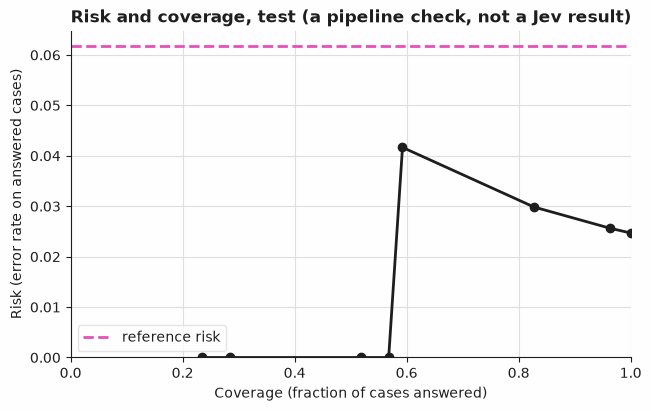

In [13]:
test_correct = [
    (score_level(a) >= helpers.BUSINESS_CUTOFF) == (g >= helpers.BUSINESS_CUTOFF)
    for a, g in zip(test_answers, test_gold, strict=True)
]
test_confidence = [a.confidence for a in test_answers]
test_accepted = [
    helpers.classify(e.fields["test_id"], a, GATE).outcome != helpers.REVIEW
    for e, a in zip(test_examples, test_answers, strict=True)
]

selective = evaluate_selective(test_correct, test_confidence, GATE)
outcomes = evaluate_outcomes(test_accepted, test_correct)
print(f"confidence-only view (evaluate_selective){check}:")
print(
    f"  answered: {selective.n_answered} of {selective.n_total} (coverage {selective.coverage:.4f}){check}"
)
print(f"  accuracy among those answered: {selective.accuracy:.4f}{check}")
print(f"  risk among those answered: {selective.risk:.4f}{check}")
print(f"the rule's own outcomes (evaluate_outcomes){check}:")
print(
    f"  answered: {outcomes.n_answered} of {outcomes.n_total} (coverage {outcomes.coverage:.4f}){check}"
)
print(f"  accuracy among those answered: {outcomes.accuracy:.4f}{check}")
print(f"  risk among those answered: {outcomes.risk:.4f}{check}")
print(
    f"agree on every field but threshold: "
    f"{(selective.n_answered, selective.coverage, selective.accuracy, selective.risk) == (outcomes.n_answered, outcomes.coverage, outcomes.accuracy, outcomes.risk)}{check}"
)
no_gate = evaluate_selective(test_correct, test_confidence, 0.0)
print(f"same split, gate removed (0.0){check}:")
print(
    f"  answered: {no_gate.n_answered} of {no_gate.n_total} (coverage {no_gate.coverage:.4f}){check}"
)
print(f"  accuracy among those answered: {no_gate.accuracy:.4f}{check}")
print(f"  risk among those answered: {no_gate.risk:.4f}{check}")

curve = selective_curve(test_correct, test_confidence)
print(f"\nrisk-coverage curve (test), each distinct confidence value as a gate{check}:")
for t, cov, acc, risk in zip(
    curve.thresholds, curve.coverage, curve.accuracy, curve.risk, strict=True
):
    print(f"  gate {t:.4f}: coverage {cov:.4f}, accuracy {acc:.4f}, risk {risk:.4f}{check}")


# How much of the two splits' confidence distribution is shared by construction, not measured
# fresh on test: a candidate's profile is its (gold level, stored probability vector). Printed
# before the figure below, not after: a figure must stay the cell's last expression, or the
# style module's PNG formatter (which hangs off the cell *result*, not merely something it runs)
# never sees it, and the committed output silently loses the chart.
def profile(example, answer, gold):
    probs = tuple(round(answer.probabilities[k], 6) for k in sorted(answer.probabilities, key=str))
    return (gold, probs)


other_split = "validation"
other_profiles = {
    profile(e, a, g) for e, a, g in zip(val_examples, val_answers, val_gold, strict=True)
}
shared = sum(
    1
    for e, a, g in zip(test_examples, test_answers, test_gold, strict=True)
    if profile(e, a, g) in other_profiles
)
print(
    f"\ntest candidates whose (gold level, stored distribution) also occurs in the "
    f"{other_split} split: {shared} of {len(test_examples)} = {shared / len(test_examples):.4f}{check}"
)

plot_risk_coverage(
    curve,
    reference_risk=1 - exact_agreement(test_gold, test_answers),
    title=f"Risk and coverage, test{check}",
)

At this gate, both candidates written to advertise coverage they do not have are confident enough (`0.71`, above `0.4800`) that the rule acts on them anyway rather than sending them to `review`; that is why `risk` above is not 0. But every one of the seven candidates this gate sends to `review` across both splits (four on `validation`, three on `test`) is one `classify`'s `relevant`/`not_relevant` decision would have judged correctly anyway: removing the gate on `test` raises coverage from `0.9630` to `1.0000` *and* raises accuracy from `0.9744` to `0.9753`, not lowers it. On this fixture set the gate costs coverage and buys nothing at the decision it actually guards -- it is kept here as a worked pattern (a confidence gate selected against the tightest criterion available, exact level agreement, which does not have to be the criterion the decision downstream actually depends on), not because these measurements show it paying for itself. The two splits also share almost all of their stored answers' shape by construction (`0.9753` of `test` candidates carry a (gold level, stored distribution) pair that also occurs somewhere in `validation`, printed above), so `test`'s numbers here are not independent corroboration of the gate chosen on `validation` -- they largely replay the same handful of authored profiles. The next section measures the further cost the gate has on the proposed suite itself.


### Task level: recall of the gold-relevant tests at the budget

Scoring candidates one at a time is not yet a proposed suite: Python groups each split's candidates back into their 19 patches and composes a suite for every one with [`propose_suite`](helpers.py), exactly as the worked examples above did for two patches. [`recall_at_budget`](../../docs/evaluation.md) (from `jev_cookbook.evaluation`) reports, for one patch, the share of *all* of that patch's gold-relevant candidates that land in the proposed suite; [`helpers.task_recall`](helpers.py) calls it on a score that reproduces `propose_suite`'s own selection exactly, with no tie left for `recall_at_budget` to average over ([`effective_scores`](helpers.py), [`effective_budget`](helpers.py) -- `tests/test_helpers.py` checks this reproduction against `propose_suite`'s own pick on every one of the 38 scored patches in this notebook's own fixtures, not only in a unit test built to show it).

The same recall is computed from the file-path-and-lexical baseline's own ranking under [`helpers.baseline_recall`](helpers.py) -- `baseline_rank`'s strict order, never the raw, possibly-tied `baseline_score` directly, so neither side of the comparison below is credited a tie-break average the other side does not also get. A baseline has no confidence gate of its own (nothing to be unconfident about), so it is unconditionally rankable on every candidate.

Both means below are a plain average of the per-patch column printed just above them, not a second, separately-derived computation of it: `jev_cookbook.evaluation.mean_recall_at_budget` assumes one shared budget across every query, which fits the baseline side (every candidate is always rankable, so `SUITE_BUDGET` applies unchanged to every patch) but not the Jev side, where `effective_budget` caps the budget to however many candidates are actually eligible for *that* patch -- a patch with one eligible candidate must not be averaged as if two were ever on offer. Averaging the already-printed column the same way on both sides keeps the two comparable and never recomputes a number the cell has already shown.


In [14]:
def group_by_task(split_examples):
    groups = {}
    for e in split_examples:
        groups.setdefault(e.fields["task_id"], []).append(e)
    return groups


def task_recalls_for(split_examples, decided_by_id, confidence_gate, budget):
    # (task_id, jev recall, baseline recall, n_relevant, n_candidates) for every patch, both
    # recalls computed by helpers.task_recall / helpers.baseline_recall -- the same functions
    # tests/test_helpers.py checks against propose_suite's own pick, so this is the only place
    # either is derived.
    rows = []
    for task_id, task_examples in sorted(group_by_task(split_examples).items()):
        cands = candidates_for(task_id, task_examples)
        classifications = {
            c.test_id: helpers.classify(c.test_id, decided_by_id[c.test_id], confidence_gate)
            for c in cands
        }
        scores = {c.test_id: decided_by_id[c.test_id].score for c in cands}
        ranks = helpers.baseline_rank(cands)
        gold_relevant = [1 if labels[c.test_id] >= helpers.BUSINESS_CUTOFF else 0 for c in cands]
        jr = helpers.task_recall(cands, classifications, scores, ranks, gold_relevant, budget)
        br = helpers.baseline_recall(cands, ranks, gold_relevant, budget)
        rows.append((task_id, jr, br, sum(gold_relevant), len(cands)))
    return rows


baseline_means = {}
for split_name, split_examples, decided, label in (
    ("validation", val_examples, val_answers, selection + check),
    ("test", test_examples, test_answers, check),
):
    decided_by_id = {e.id: a for e, a in zip(split_examples, decided, strict=True)}
    rows = task_recalls_for(split_examples, decided_by_id, GATE, helpers.SUITE_BUDGET)
    print(f"{split_name}, {len(rows)} patches{label}")
    for task_id, jr, br, n_rel, n_cand in rows:
        print(
            f"  {task_id:24s} jev recall {jr:.4f}  baseline recall {br:.4f}  ({n_rel} of {n_cand} relevant){label}"
        )
    mean_jev = sum(jr for _, jr, _, _, _ in rows) / len(rows)
    mean_baseline = sum(br for _, _, br, _, _ in rows) / len(rows)
    baseline_means[split_name] = mean_baseline
    print(f"  mean recall at budget, jev:      {mean_jev:.4f}{label}")
    print(f"  mean recall at budget, baseline: {mean_baseline:.4f}{label}")
    print()

validation, 19 patches (a selection step, not a reported result) (a pipeline check, not a Jev result)
  v-csv-writer             jev recall 1.0000  baseline recall 1.0000  (1 of 4 relevant) (a selection step, not a reported result) (a pipeline check, not a Jev result)
  v-digest-scheduler       jev recall 1.0000  baseline recall 1.0000  (1 of 4 relevant) (a selection step, not a reported result) (a pipeline check, not a Jev result)
  v-discount-engine        jev recall 1.0000  baseline recall 0.0000  (1 of 4 relevant) (a selection step, not a reported result) (a pipeline check, not a Jev result)
  v-funnel-tracker         jev recall 0.6667  baseline recall 0.6667  (3 of 5 relevant) (a selection step, not a reported result) (a pipeline check, not a Jev result)
  v-invite-flow            jev recall 0.6667  baseline recall 0.6667  (3 of 5 relevant) (a selection step, not a reported result) (a pipeline check, not a Jev result)
  v-query-parser           jev recall 1.0000  baseline recall 1

Every patch's recall is computed against *that patch's own* count of gold-relevant candidates, so at the budget shown here (`SUITE_BUDGET`, 2) a patch with three relevant candidates can never reach `1.0000` no matter how the ranking falls -- and several patches in both splits do exactly that, which is why the mean here is well short of a perfect score. This fixture set was written so several patches have more gold-relevant candidates than the budget can ever hold ("budget" patches) and several others have exactly as many as the budget holds but one of them stored at too low a confidence to be trusted ("gate" patches). Removing the budget alone would recover the first kind but not the second -- a "gate" patch's low-confidence candidate stays excluded whatever the budget is, so the mean would still fall short of `1.0000` -- and the next section measures exactly that, and what removing the gate recovers instead.

Jev's mean recall is `0.8509` on `validation` and `0.8333` on `test`; the baseline's is `0.8509` on `validation` -- an exact tie -- and `0.8684` on `test`, ahead there. The baseline has no confidence gate of its own to turn a high-scoring candidate away, so it never pays the gate's own cost on `role-assignment` and `version-diff`, where it reaches `1.0000` against Jev's gated `0.5000`: a real cost of keeping a confidence gate selected the way "Python's part" and "Selective prediction" describe, paid here in recall as well as in coverage. `recurrence-expander`, the third "gate" patch, is not like the other two: the baseline's own deterministic order also fails to rank its gold-relevant `exercises_change` candidate inside the budget, so the two tie at `0.5000` there too. The baseline also has no way to notice when a candidate's wording defeats its word-overlap count: on `discount-engine` (`validation`), the one patch written for exactly this (the "Candidate sets" section above), the baseline's recall under its own stated order is `0.0000` against Jev's `1.0000`. Its two budget slots go to the `same_area` candidate (the clear winner, reusing several of the patch's own words) and, on a tie at a baseline score of `2.0`, to an in-area filler candidate (it lives under the same `billing` area as the changed file, which is where its half of the tied score comes from) -- a tie the direct-regression candidate loses on listed position, having been paraphrased to share no words with the patch on purpose. This deliberate blind spot does not transfer to `test`: there, the direct-regression candidate's wording happens to share one of the patch's own words where the `validation` variant shares none, so it wins its slot outright by a point (baseline score `3.0` against the same filler's `2.0`) rather than needing to win any tie, and the baseline's recall there is `1.0000` (the table above). And on `ticket-router` (`test`), the candidate written to advertise coverage it does not have was *also* worded to echo the patch's own vocabulary and feature area, so it fools the baseline exactly as it fools the gate: both land on the same wrong pair of two candidates, recall `0.3333` either way.

So the baseline's edge on `test` is real, but it is not evidence that the lexical signal beats the semantic one: it is the confidence gate's own cost (`role-assignment`, `version-diff`) outweighing what the semantic score buys back on `discount-engine`. The next section removes the gate and shows exactly that.


### What the confidence gate and the size budget each cost

A mechanism that cannot change a number this notebook reports would not be teaching anything by being here. The cell below deletes each mechanism in turn -- the confidence gate (set to `0.0`, so nothing is ever sent to `review`), the size budget (set large enough that it can never bind), and both together -- and recomputes the same mean recall, so the cost of each is a number on the page, not a claim about the code.


In [15]:
def mean_jev_recall(split_examples, decided_by_id, confidence_gate, budget):
    vals = []
    for task_id, task_examples in sorted(group_by_task(split_examples).items()):
        cands = candidates_for(task_id, task_examples)
        classifications = {
            c.test_id: helpers.classify(c.test_id, decided_by_id[c.test_id], confidence_gate)
            for c in cands
        }
        scores = {c.test_id: decided_by_id[c.test_id].score for c in cands}
        ranks = helpers.baseline_rank(cands)
        gold_relevant = [1 if labels[c.test_id] >= helpers.BUSINESS_CUTOFF else 0 for c in cands]
        vals.append(
            helpers.task_recall(cands, classifications, scores, ranks, gold_relevant, budget)
        )
    return sum(vals) / len(vals)


for split_name, split_examples, decided, label in (
    ("validation", val_examples, val_answers, selection + check),
    ("test", test_examples, test_answers, check),
):
    decided_by_id = {e.id: a for e, a in zip(split_examples, decided, strict=True)}
    with_both = mean_jev_recall(split_examples, decided_by_id, GATE, helpers.SUITE_BUDGET)
    no_gate = mean_jev_recall(split_examples, decided_by_id, 0.0, helpers.SUITE_BUDGET)
    no_budget = mean_jev_recall(split_examples, decided_by_id, GATE, 1000)
    no_either = mean_jev_recall(split_examples, decided_by_id, 0.0, 1000)
    print(f"{split_name}{label}")
    print(
        f"  as proposed (gate {GATE:.4f}, budget {helpers.SUITE_BUDGET}):      {with_both:.4f}{label}"
    )
    print(
        f"  gate removed (gate 0.0, budget {helpers.SUITE_BUDGET}):            {no_gate:.4f}  (+{no_gate - with_both:.4f}){label}"
    )
    print(
        f"  budget removed (gate {GATE:.4f}, budget unbounded):       {no_budget:.4f}  (+{no_budget - with_both:.4f}){label}"
    )
    print(
        f"  both removed (gate 0.0, budget unbounded):          {no_either:.4f}  (+{no_either - with_both:.4f}){label}"
    )
    print(
        f"  baseline mean recall, for reference:                {baseline_means[split_name]:.4f}{label}"
    )
    print()

# Why "both removed" reaches exactly 1.0000: a false negative (gold level clears BUSINESS_CUTOFF
# but the modal level does not) is the one thing no gate or budget change could ever recover,
# because such a candidate is never eligible for the suite to begin with. Counted directly,
# across both splits, rather than asserted.
false_negatives = sum(
    1
    for a, g in zip(val_answers + test_answers, val_gold + test_gold, strict=True)
    if g >= helpers.BUSINESS_CUTOFF and score_level(a) < helpers.BUSINESS_CUTOFF
)
print(f"false negatives across both splits: {false_negatives}{check}")

validation (a selection step, not a reported result) (a pipeline check, not a Jev result)
  as proposed (gate 0.4800, budget 2):      0.8509 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  gate removed (gate 0.0, budget 2):            0.9298  (+0.0789) (a selection step, not a reported result) (a pipeline check, not a Jev result)
  budget removed (gate 0.4800, budget unbounded):       0.9211  (+0.0702) (a selection step, not a reported result) (a pipeline check, not a Jev result)
  both removed (gate 0.0, budget unbounded):          1.0000  (+0.1491) (a selection step, not a reported result) (a pipeline check, not a Jev result)
  baseline mean recall, for reference:                0.8509 (a selection step, not a reported result) (a pipeline check, not a Jev result)

test (a pipeline check, not a Jev result)
  as proposed (gate 0.4800, budget 2):      0.8333 (a pipeline check, not a Jev result)
  gate removed (gate 0.0, budget 2):            0.9123  (+0.

Both the gate and the budget raise the mean recall when removed on both splits, so neither is a branch that could be deleted from this recipe without changing what it reports. They also bind on different patches: `role-assignment` (above) only moves when the gate is removed, and `ticket-router` only moves when the budget is removed -- `tests/test_helpers.py` checks that at least one patch in this notebook's own fixtures moves each way, so this is not an artifact of the two patches chosen for the worked examples. Removing *both* recovers mean recall of exactly `1.0000` on both splits: the false-negative count above is `0` -- no candidate anywhere in either split has a gold level that clears `BUSINESS_CUTOFF` while its own modal level does not -- so the gate and the budget are the only two things standing between this pipeline and perfect recall on this fixture set.

This settles what "Task level" above actually found. Removing only the gate's `0.0789` cost already puts the pipeline at `0.9298` (`validation`) and `0.9123` (`test`) -- ahead of the baseline's `0.8509` and `0.8684` on both splits, comfortably. The baseline was never ahead of what Jev's relevance score can do here; it was ahead of what this recipe's confidence gate, selected against a stricter criterion than the decision it guards (see "Python's part" and "Selective prediction"), left on the table. The lesson this fixture set actually supports is not "the lexical baseline beats the semantic score" -- it is that **a confidence gate chosen against the wrong correctness criterion can lose a pipeline a comparison it would otherwise win**, and that this is only visible by measuring the decision the gate actually guards, not the one it happens to be selected against.


## What was and was not measured

Measured: that the pipeline runs end to end, and that the rule, the baseline, and the suite-composition function behave as designed on 160 scored candidates across 38 patches (plus 3 more, shown in this notebook but never scored). Not measured: anything about how Jev performs, how fast it is, or what it costs. The stored answers in the offline run are written by hand as probabilities, some of them wrong on purpose (including two wrong *and* confident, to show what a frozen confidence gate does not catch, and one of those also written to cost a real candidate its place in a budget-limited suite), so every number above describes this fixture set and not a model.


In [16]:
demo_examples = [e for e in examples if e.split == "demo"]
all_patches = {e.fields["task_id"] for e in examples}
if offline:
    print(f"Provenance: {backend.mode}. Not measured live: a pipeline check, not a Jev result.")
    print(f"N: {len(val_examples)} validation and {len(test_examples)} test candidates{check}")
else:
    dates = ", ".join(getattr(backend, "recorded_dates", ()) or ()) or "this run"
    print(f"Provenance: {backend.mode}, model {backend.model}")
    print(f"Captured: {dates}")
    print(f"N: {len(val_examples)} validation and {len(test_examples)} test candidates")
scored_patches = val_n_patches + test_n_patches
print(
    f"fixtures: {len(examples)} total candidates across {len(all_patches)} patches "
    f"({len(scored)} scored across {scored_patches} scored patches, "
    f"{len(demo_examples)} demo across {len(all_patches) - scored_patches} demo patches){check}"
)
print(f"requests this notebook actually made (len(answered)): {len(answered)}{check}")

Provenance: synthetic. Not measured live: a pipeline check, not a Jev result.
N: 79 validation and 81 test candidates (a pipeline check, not a Jev result)
fixtures: 163 total candidates across 40 patches (160 scored across 38 scored patches, 3 demo across 2 demo patches) (a pipeline check, not a Jev result)
requests this notebook actually made (len(answered)): 163 (a pipeline check, not a Jev result)


## Next steps

- Add a hard candidate to `ROWS` in `build_fixtures.py` with the answer you expect a model might give, run `python build_fixtures.py`, and see where `classify` and `propose_suite` place it.
- Change `helpers.SUITE_BUDGET` from `2` to `1` or `3` in the `counterfactual-code` cell's call (pass it directly instead of `helpers.SUITE_BUDGET`) and see how the mean recall moves on both splits.
- Change the confidence gate's `min_coverage` in the `python-rule` cell, under "Python's part" (`0.8` to something looser or tighter), and see how the chosen gate, and the recall it costs, move together.
- Neighbouring recipes: [`17-passage-reranking`](../17-passage-reranking/) (another `Score` question over candidate sets, ranking retrieved passages rather than proposing a bounded suite) and [`03-response-clarity-scoring`](../03-response-clarity-scoring/) (a `Score` question over a single piece of text, with no candidate set at all).
